# 2. Position/velocity tracking

**Goal:** travel to position 2 with zero terminal velocity.
Let $x_k=(p_k,v_k)$ and $u_k=a_k$.

$$\begin{aligned}
\min\quad &\frac12\sum_{k=0}^{N}(x_k-x_{\rm target})^TQ_k(x_k-x_{\rm target})
          +\frac12\sum_{k=0}^{N-1}0.15a_k^2\\
\text{subject to}\quad &p_{k+1}=p_k+\Delta t\,v_k+\tfrac12\Delta t^2a_k,\\
&v_{k+1}=v_k+\Delta t\,a_k,\quad x_0=(0,0),\quad x_N=(2,0),\\
&|a_k|\le1.2,\quad |v_k|\le1.
\end{aligned}$$


Run the cells from top to bottom. The first `Solver(...)` may compile the native
library. That is setup, not solve time. Installation instructions: [README](../README.md).

All model arrays are constructed below: there is no hidden model builder.
`explain_solution` only checks and reports the already-computed solution.

> **Development transparency:** Substantial portions of ICORE's implementation and documentation were generated and revised with GPT under human direction. Not all details have undergone independent human review. See the [development and review statement](../README.md#development-transparency-and-review-status).


In [1]:
# Locate the repository whether Jupyter starts here or in the parent folder.
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "icore" / "api.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
from icore import Solver
from example_tools.tutorial import explain_solution

BACKEND = "cpp"           # "c" or "cpp"; both use the same numerical algorithm.
TOLERANCE = 1e-8
USE_PRESOLVE = True
DETAILED = False           # True: one extra untimed replay, with expandable details.

## 1. Dimensions and dynamics

In [2]:
N, nx, nu = 30, 2, 1
dt = 0.2
A = np.tile([[1.0, dt], [0.0, 1.0]], (N, 1, 1))
B = np.tile([[0.5 * dt**2], [dt]], (N, 1, 1))
b = np.zeros((N, nx))
x0 = np.zeros(nx)
target = np.array([2.0, 0.0])

## 2. Tracking objective
Expanding $\tfrac12(x-x_{\rm target})^TQ(x-x_{\rm target})$ gives `q = -Q @ target`.
The remaining constant changes the reported objective, not the optimizer.

In [3]:
Q = np.tile(np.diag([4.0, 0.3]), (N + 1, 1, 1))
Q[-1] = np.diag([20.0, 2.0])
R = 0.15 * np.ones((N, nu, nu))
S = np.zeros((N, nu, nx))
q = -(Q @ target)
r = np.zeros((N, nu))
# The solver need not see a constant; add it back only when reporting the objective.
objective_offset = 0.5 * sum(target @ Qk @ target for Qk in Q)

## 3. Bounds and terminal equality
The terminal condition is an exact equality, not two opposite inequalities.

In [4]:
# Columns are [acceleration, position, velocity].
G = np.zeros((N + 1, 4, nu + nx))
h = np.ones((N + 1, 4))
G[:N, 0, 0], G[:N, 1, 0] = 1.0, -1.0
h[:, :2] = 1.2
G[:, 2, 2], G[:, 3, 2] = 1.0, -1.0
h[:, 2:] = 1.0
F = np.eye(nx)
f = target.copy()

## 4. Give the arrays to ICORE and solve

`[u, x]` is the column order in each constraint row. The block cost is
$\tfrac12x^TQx + u^TSx + \tfrac12u^TRu + q^Tx + r^Tu$.
`F @ x[N] = f` is an optional terminal equality. An empty `F, f` means none.

The kernel and counters below come from the actual solve. A factorization policy
is **not** claimed to be a trace of every operation. Set `DETAILED=True` above
for an additional diagnostic replay; it is separate from solve timing.

In [5]:
problem = dict(
    A=A, B=B, b=b, x0=x0,
    Q=Q, R=R, S=S, q=q, r=r,
    G=G, h=h, F=F, f=f,
)

with Solver(problem, backend=BACKEND, tolerance=TOLERANCE,
            structural_presolve=USE_PRESOLVE) as solver:
    solution = solver.solve()
    report = explain_solution(solver, solution, problem,
                              objective_offset=objective_offset, detailed=DETAILED)

# Solver returns your original coordinates, including when presolve was applied.
x = solution["x"]        # Shape (N + 1, nx).
u = solution["u"]        # Shape (N, nu); there is no terminal control.
print("Initial state:", x[0])
print("Final state:", x[-1])
print("First input:", u[0])

### What the solver actually did

Property,Value
Backend,C++
Status / iterations,Passed / 7
Native solve (ms),0.130000
Structural presolve requested,Yes
Exact OCP-to-chain reduction applied,No
Actual kernel,General OCP / Riccati kernel
Reason,The general stage-structured OCP representation was retained.
Factorization policy (not a trace),Automatic Riccati; QR recovery supports terminal equalities
Factor retries / refinement steps,0 / 0
Dense-to-OCP numerical fallbacks,0


The optional chain-reduction certificate was rejected; keeping the general OCP is expected, not an error.

### Accuracy in the original problem

primal error,dual error,complementarity,dynamics error,terminal error,objective (including constant),passed
4.441e-16,7.105e-15,1.239e-10,4.441e-16,3.283e-24,48.413522,True


Native solve time excludes compilation, model setup, this audit, and plotting. Counters do not list every factorization attempt or every reason a fast path was rejected.

Initial state: [0. 0.]
Final state: [ 2.00000000e+00 -3.28319112e-24]
First input: [1.2]


## 5. Results

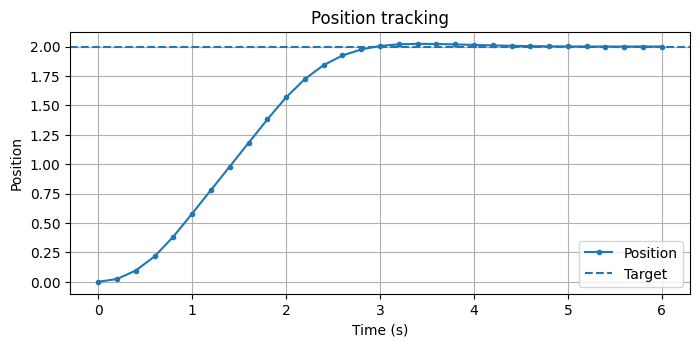

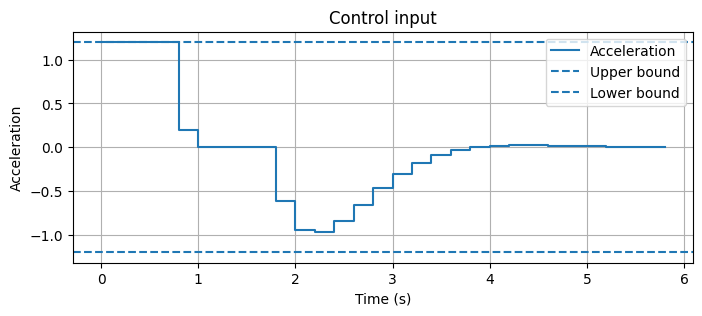

In [6]:
time_x = dt * np.arange(N + 1)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(time_x, x[:, 0], marker=".", label="Position")
ax.axhline(target[0], linestyle="--", label="Target")
ax.set(xlabel="Time (s)", ylabel="Position", title="Position tracking")
ax.grid(True)
ax.legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.0))
ax.step(dt * np.arange(N), u[:, 0], where="post", label="Acceleration")
ax.axhline(1.2, linestyle="--", label="Upper bound")
ax.axhline(-1.2, linestyle="--", label="Lower bound")
ax.set(xlabel="Time (s)", ylabel="Acceleration", title="Control input")
ax.grid(True)
ax.legend()
plt.show()

## Adapt this model
Replace the matrices with your linear dynamics or the current convex subproblem's linearization.
Update `target`, `q`, and `f` together when changing the desired terminal state.
Use consistent units for position, velocity, acceleration, and time.

Next: [input-rate limits with a memory state](03_input_rate_limits.ipynb).